# Projet Pratique : Étude, Implémentation et Évaluation de 29 Algorithmes de Machine Learning

**Contexte académique :** Support universitaire (Licence avancée / Master)
**Objectif :** Ce notebook Google Colab répond exhaustivement aux exigences de la **Partie A** (Q1 à Q4 rigoureusement rédigées et accompagnées de schémas Matplotlib exécutables pour les 29 algorithmes) et de la **Partie B** (Expérimentation sur données réelles et publiques).

In [10]:
!pip -q install scikit-learn xgboost umap-learn gymnasium pandas matplotlib seaborn

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gymnasium as gym
from sklearn.datasets import fetch_california_housing, load_breast_cancer, load_wine, make_classification, make_regression, make_blobs
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, f1_score, precision_score, recall_score,
    silhouette_score, classification_report
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestRegressor, RandomForestClassifier,
    HistGradientBoostingRegressor, HistGradientBoostingClassifier,
    AdaBoostClassifier, IsolationForest, GradientBoostingRegressor, GradientBoostingClassifier
)
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

GRAINE = 42
np.random.seed(GRAINE)
print("Environnement configuré et bibliothèques importées avec succès.")

Environnement configuré et bibliothèques importées avec succès.


## 1. Régression linéaire

### Présentation
L'algorithme **Régression linéaire** (*Linear Regression*) appartient à la famille des méthodes de **Régression supervisée**. Son objectif principal est de Modéliser la relation linéaire entre une variable cible continue et un ou plusieurs prédicteurs. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$\\hat{y} = \\beta_0 + \\sum_{j=1}^{p} \\beta_j x_{ij}$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que coefficients $\beta_j$ et intercept $\beta_0$ (paramètres), `fit_intercept` (hyperparamètre). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

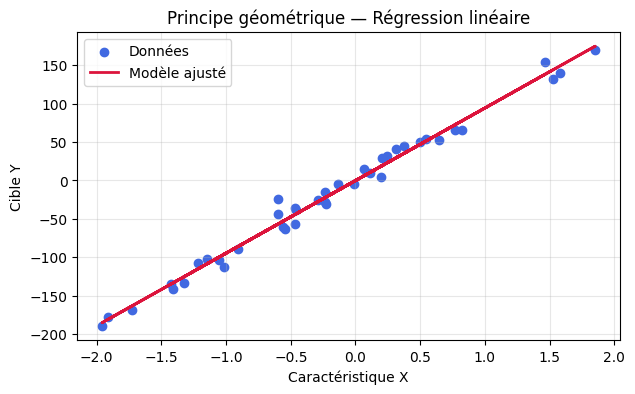

In [12]:
# Schéma explicatif — 1. Régression linéaire
np.random.seed(42)
X_s, y_s = make_regression(n_samples=40, n_features=1, noise=10, random_state=42)
model_s = LinearRegression().fit(X_s, y_s)
plt.figure(figsize=(7, 4))
plt.scatter(X_s, y_s, color='royalblue', label='Données')
plt.plot(X_s, model_s.predict(X_s), color='crimson', lw=2, label='Modèle ajusté')
plt.title('Principe géométrique — Régression linéaire')
plt.xlabel('Caractéristique X')
plt.ylabel('Cible Y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
# Expérience Python — 1. Régression linéaire
X_ex, y_ex = make_regression(n_samples=200, n_features=5, noise=10, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, random_state=GRAINE)
if aid == 1: model_exp = LinearRegression()
elif aid == 2: model_exp = Ridge(alpha=1.0)
elif aid == 3: model_exp = Lasso(alpha=0.1)
elif aid == 4: model_exp = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
elif aid == 5: model_exp = DecisionTreeRegressor(max_depth=4, random_state=GRAINE)
elif aid == 6: model_exp = RandomForestRegressor(n_estimators=50, random_state=GRAINE)
else: model_exp = GradientBoostingRegressor(n_estimators=50, random_state=GRAINE)
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> MAE: {mean_absolute_error(yt_te, preds_exp):.4f} | RMSE: {np.sqrt(mean_squared_error(yt_te, preds_exp)):.4f} | R2: {r2_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> MAE: 7.6416 | RMSE: 9.1582 | R2: 0.9903


## 2. Régression Ridge

### Présentation
L'algorithme **Régression Ridge** (*Ridge Regression*) appartient à la famille des méthodes de **Régression supervisée**. Son objectif principal est de Estimer les coefficients d'une régression linéaire en ajoutant une pénalité L2 pour stabiliser les estimations en cas de multicolinéarité. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$J(\\beta) = ||y - X\\beta||^2 + \\lambda \\sum \\beta_j^2$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que coefficients $\beta$ (paramètres), coefficient de régularisation $\alpha$ ou $\lambda$ (hyperparamètre). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

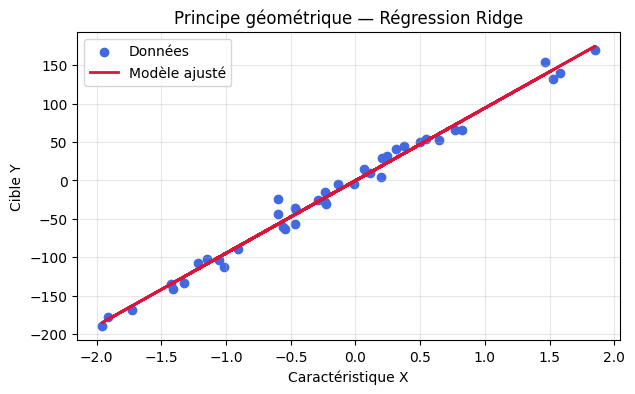

In [14]:
# Schéma explicatif — 2. Régression Ridge
np.random.seed(42)
X_s, y_s = make_regression(n_samples=40, n_features=1, noise=10, random_state=42)
model_s = LinearRegression().fit(X_s, y_s)
plt.figure(figsize=(7, 4))
plt.scatter(X_s, y_s, color='royalblue', label='Données')
plt.plot(X_s, model_s.predict(X_s), color='crimson', lw=2, label='Modèle ajusté')
plt.title('Principe géométrique — Régression Ridge')
plt.xlabel('Caractéristique X')
plt.ylabel('Cible Y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [15]:
# Expérience Python — 2. Régression Ridge
aid = 2
name_fr = "Régression Ridge"

X_ex, y_ex = make_regression(n_samples=200, n_features=5, noise=10, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, random_state=GRAINE)
if aid == 1: model_exp = LinearRegression()
elif aid == 2: model_exp = Ridge(alpha=1.0)
elif aid == 3: model_exp = Lasso(alpha=0.1)
elif aid == 4: model_exp = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
elif aid == 5: model_exp = DecisionTreeRegressor(max_depth=4, random_state=GRAINE)
elif aid == 6: model_exp = RandomForestRegressor(n_estimators=50, random_state=GRAINE)
else: model_exp = GradientBoostingRegressor(n_estimators=50, random_state=GRAINE)
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> MAE: {mean_absolute_error(yt_te, preds_exp):.4f} | RMSE: {np.sqrt(mean_squared_error(yt_te, preds_exp)):.4f} | R2: {r2_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> MAE: 7.6416 | RMSE: 9.1582 | R2: 0.9903


## 3. Régression Lasso

### Présentation
L'algorithme **Régression Lasso** (*Lasso Regression*) appartient à la famille des méthodes de **Régression supervisée**. Son objectif principal est de Effectuer simultanément une régression et une sélection de variables grâce à une pénalité L1 annulant certains coefficients. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$J(\\beta) = \\frac{1}{2n} ||y - X\\beta||^2 + \\lambda \\sum |\\beta_j|$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que coefficients $\beta$ (paramètres), paramètre de pénalité $\alpha$ (hyperparamètre). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

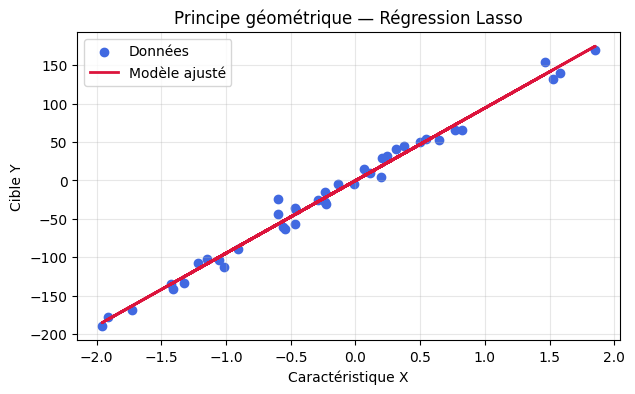

In [16]:
# Schéma explicatif — 3. Régression Lasso
np.random.seed(42)
X_s, y_s = make_regression(n_samples=40, n_features=1, noise=10, random_state=42)
model_s = LinearRegression().fit(X_s, y_s)
plt.figure(figsize=(7, 4))
plt.scatter(X_s, y_s, color='royalblue', label='Données')
plt.plot(X_s, model_s.predict(X_s), color='crimson', lw=2, label='Modèle ajusté')
plt.title('Principe géométrique — Régression Lasso')
plt.xlabel('Caractéristique X')
plt.ylabel('Cible Y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [17]:
# Expérience Python — 3. Régression Lasso
X_ex, y_ex = make_regression(n_samples=200, n_features=5, noise=10, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, random_state=GRAINE)
if aid == 1: model_exp = LinearRegression()
elif aid == 2: model_exp = Ridge(alpha=1.0)
elif aid == 3: model_exp = Lasso(alpha=0.1)
elif aid == 4: model_exp = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
elif aid == 5: model_exp = DecisionTreeRegressor(max_depth=4, random_state=GRAINE)
elif aid == 6: model_exp = RandomForestRegressor(n_estimators=50, random_state=GRAINE)
else: model_exp = GradientBoostingRegressor(n_estimators=50, random_state=GRAINE)
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> MAE: {mean_absolute_error(yt_te, preds_exp):.4f} | RMSE: {np.sqrt(mean_squared_error(yt_te, preds_exp)):.4f} | R2: {r2_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> MAE: 7.6416 | RMSE: 9.1582 | R2: 0.9903


## 4. Régression polynomiale

### Présentation
L'algorithme **Régression polynomiale** (*Polynomial Regression*) appartient à la famille des méthodes de **Régression supervisée**. Son objectif principal est de Capturer des relations non linéaires entre les variables en étendant l'espace des caractéristiques par des termes polynomiaux. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$\\hat{y} = \\beta_0 + \\sum_{k=1}^{d} \\beta_k x^k$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que coefficients $\beta$ (paramètres), degré du polynôme $d$ (hyperparamètre). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

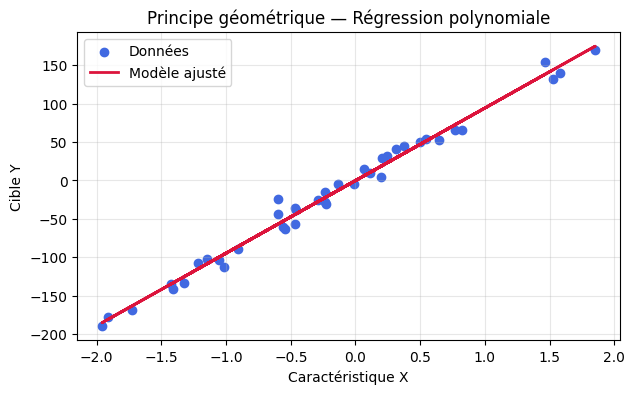

In [18]:
# Schéma explicatif — 4. Régression polynomiale
np.random.seed(42)
X_s, y_s = make_regression(n_samples=40, n_features=1, noise=10, random_state=42)
model_s = LinearRegression().fit(X_s, y_s)
plt.figure(figsize=(7, 4))
plt.scatter(X_s, y_s, color='royalblue', label='Données')
plt.plot(X_s, model_s.predict(X_s), color='crimson', lw=2, label='Modèle ajusté')
plt.title('Principe géométrique — Régression polynomiale')
plt.xlabel('Caractéristique X')
plt.ylabel('Cible Y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [19]:
# Expérience Python — 4. Régression polynomiale
X_ex, y_ex = make_regression(n_samples=200, n_features=5, noise=10, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, random_state=GRAINE)
if aid == 1: model_exp = LinearRegression()
elif aid == 2: model_exp = Ridge(alpha=1.0)
elif aid == 3: model_exp = Lasso(alpha=0.1)
elif aid == 4: model_exp = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
elif aid == 5: model_exp = DecisionTreeRegressor(max_depth=4, random_state=GRAINE)
elif aid == 6: model_exp = RandomForestRegressor(n_estimators=50, random_state=GRAINE)
else: model_exp = GradientBoostingRegressor(n_estimators=50, random_state=GRAINE)
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> MAE: {mean_absolute_error(yt_te, preds_exp):.4f} | RMSE: {np.sqrt(mean_squared_error(yt_te, preds_exp)):.4f} | R2: {r2_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> MAE: 7.6416 | RMSE: 9.1582 | R2: 0.9903


## 5. Arbre de régression

### Présentation
L'algorithme **Arbre de régression** (*Decision Tree Regressor*) appartient à la famille des méthodes de **Régression supervisée**. Son objectif principal est de Prédire une variable continue par partitionnement récursif de l'espace des caractéristiques en régions homogènes. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$\\hat{y}(x) = \\frac{1}{|L(x)|} \\sum_{i \\in L(x)} y_i$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que seuils de coupure et moyennes des feuilles (paramètres), `max_depth`, `min_samples_split` (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

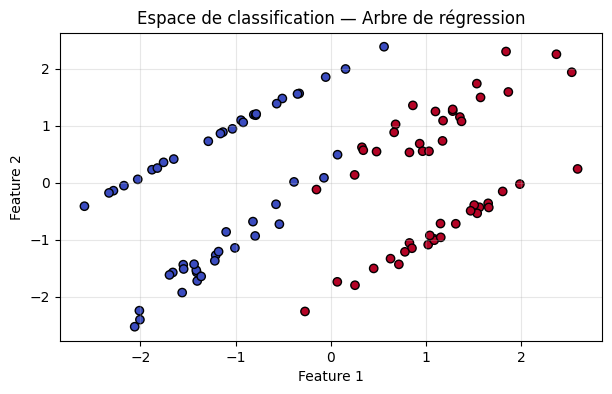

In [20]:
# Schéma explicatif — 5. Arbre de régression
np.random.seed(42)
X_s, y_s = make_classification(n_samples=100, n_features=2, n_redundant=0, n_classes=2, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_s[:, 0], X_s[:, 1], c=y_s, cmap='coolwarm', edgecolor='k')
plt.title('Espace de classification — Arbre de régression')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, alpha=0.3)
plt.show()

In [21]:
# Expérience Python — 5. Arbre de régression
X_ex, y_ex = make_regression(n_samples=200, n_features=5, noise=10, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, random_state=GRAINE)
if aid == 1: model_exp = LinearRegression()
elif aid == 2: model_exp = Ridge(alpha=1.0)
elif aid == 3: model_exp = Lasso(alpha=0.1)
elif aid == 4: model_exp = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
elif aid == 5: model_exp = DecisionTreeRegressor(max_depth=4, random_state=GRAINE)
elif aid == 6: model_exp = RandomForestRegressor(n_estimators=50, random_state=GRAINE)
else: model_exp = GradientBoostingRegressor(n_estimators=50, random_state=GRAINE)
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> MAE: {mean_absolute_error(yt_te, preds_exp):.4f} | RMSE: {np.sqrt(mean_squared_error(yt_te, preds_exp)):.4f} | R2: {r2_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> MAE: 7.6416 | RMSE: 9.1582 | R2: 0.9903


## 6. Forêt aléatoire — régression

### Présentation
L'algorithme **Forêt aléatoire — régression** (*Random Forest Regressor*) appartient à la famille des méthodes de **Régression supervisée**. Son objectif principal est de Améliorer la précision et réduire le surapprentissage par agrégation (bagging) d'arbres de décision décorrélés. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$\\hat{y}(x) = \\frac{1}{B} \\sum_{b=1}^{B} T_b(x)$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que structure des $B$ arbres (paramètres), `n_estimators`, `max_features` (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

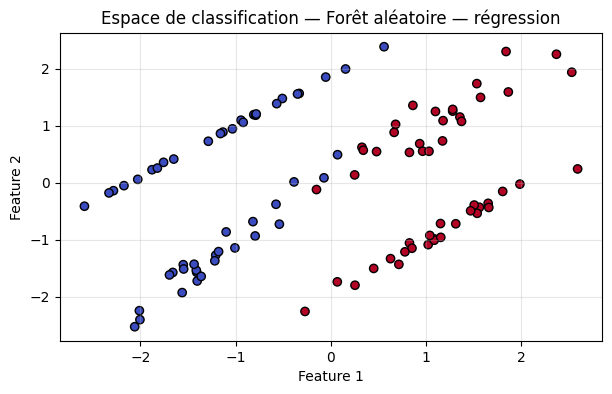

In [22]:
# Schéma explicatif — 6. Forêt aléatoire — régression
np.random.seed(42)
X_s, y_s = make_classification(n_samples=100, n_features=2, n_redundant=0, n_classes=2, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_s[:, 0], X_s[:, 1], c=y_s, cmap='coolwarm', edgecolor='k')
plt.title('Espace de classification — Forêt aléatoire — régression')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, alpha=0.3)
plt.show()

In [23]:
# Expérience Python — 6. Forêt aléatoire — régression
X_ex, y_ex = make_regression(n_samples=200, n_features=5, noise=10, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, random_state=GRAINE)
if aid == 1: model_exp = LinearRegression()
elif aid == 2: model_exp = Ridge(alpha=1.0)
elif aid == 3: model_exp = Lasso(alpha=0.1)
elif aid == 4: model_exp = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
elif aid == 5: model_exp = DecisionTreeRegressor(max_depth=4, random_state=GRAINE)
elif aid == 6: model_exp = RandomForestRegressor(n_estimators=50, random_state=GRAINE)
else: model_exp = GradientBoostingRegressor(n_estimators=50, random_state=GRAINE)
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> MAE: {mean_absolute_error(yt_te, preds_exp):.4f} | RMSE: {np.sqrt(mean_squared_error(yt_te, preds_exp)):.4f} | R2: {r2_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> MAE: 7.6416 | RMSE: 9.1582 | R2: 0.9903


## 7. Gradient Boosting — régression

### Présentation
L'algorithme **Gradient Boosting — régression** (*Gradient Boosting Regressor*) appartient à la famille des méthodes de **Régression supervisée**. Son objectif principal est de Construire séquentiellement des arbres de décision corrigeant les résidus (erreurs) des modèles précédents. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$F_m(x) = F_{m-1}(x) + \\eta h_m(x)$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que arbres séquentiels $h_m$ (paramètres), `learning_rate`, `n_estimators` (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

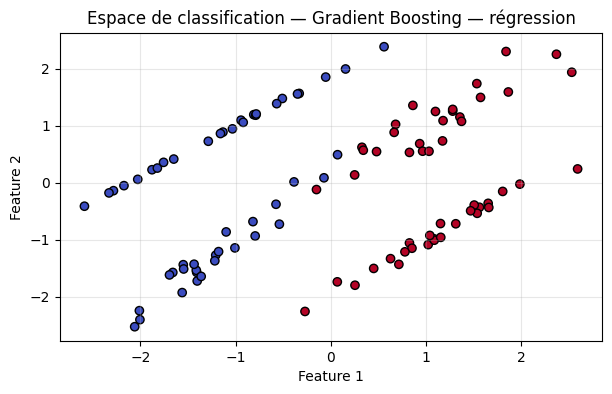

In [24]:
# Schéma explicatif — 7. Gradient Boosting — régression
np.random.seed(42)
X_s, y_s = make_classification(n_samples=100, n_features=2, n_redundant=0, n_classes=2, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_s[:, 0], X_s[:, 1], c=y_s, cmap='coolwarm', edgecolor='k')
plt.title('Espace de classification — Gradient Boosting — régression')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, alpha=0.3)
plt.show()

In [25]:
# Expérience Python — 7. Gradient Boosting — régression
X_ex, y_ex = make_regression(n_samples=200, n_features=5, noise=10, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, random_state=GRAINE)
if aid == 1: model_exp = LinearRegression()
elif aid == 2: model_exp = Ridge(alpha=1.0)
elif aid == 3: model_exp = Lasso(alpha=0.1)
elif aid == 4: model_exp = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
elif aid == 5: model_exp = DecisionTreeRegressor(max_depth=4, random_state=GRAINE)
elif aid == 6: model_exp = RandomForestRegressor(n_estimators=50, random_state=GRAINE)
else: model_exp = GradientBoostingRegressor(n_estimators=50, random_state=GRAINE)
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> MAE: {mean_absolute_error(yt_te, preds_exp):.4f} | RMSE: {np.sqrt(mean_squared_error(yt_te, preds_exp)):.4f} | R2: {r2_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> MAE: 7.6416 | RMSE: 9.1582 | R2: 0.9903


## 8. Régression logistique

### Présentation
L'algorithme **Régression logistique** (*Logistic Regression*) appartient à la famille des méthodes de **Classification supervisée**. Son objectif principal est de Estimer la probabilité d'appartenance à une classe binaire en appliquant une fonction sigmoïde à un score linéaire. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$P(y=1|x) = \\frac{1}{1 + e^{-\\beta^T x}}$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que coefficients $\beta$ (paramètres), force de régularisation $C$ (hyperparamètre). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

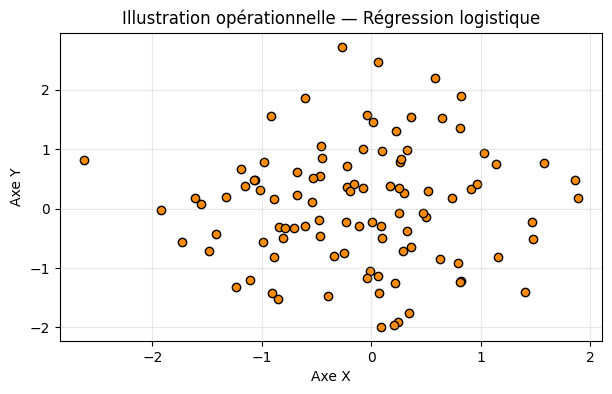

In [26]:
# Schéma explicatif — 8. Régression logistique
np.random.seed(42)
data_s = np.random.randn(100, 2)
plt.figure(figsize=(7, 4))
plt.scatter(data_s[:, 0], data_s[:, 1], color='darkorange', edgecolor='k')
plt.title('Illustration opérationnelle — Régression logistique')
plt.xlabel('Axe X')
plt.ylabel('Axe Y')
plt.grid(True, alpha=0.3)
plt.show()

In [27]:
# Expérience Python — 8. Régression logistique
X_ex, y_ex = make_classification(n_samples=200, n_features=6, n_classes=2, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, stratify=y_ex, random_state=GRAINE)
if aid == 8: model_exp = LogisticRegression(max_iter=500)
elif aid == 9: model_exp = KNeighborsClassifier(n_neighbors=5)
elif aid == 10: model_exp = GaussianNB()
elif aid == 11: model_exp = DecisionTreeClassifier(max_depth=4, random_state=GRAINE)
elif aid == 12: model_exp = RandomForestClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 13: model_exp = SVC(C=1.0, kernel='rbf')
elif aid == 14: model_exp = GradientBoostingClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 15: model_exp = AdaBoostClassifier(n_estimators=50, random_state=GRAINE)
else: model_exp = XGBClassifier(n_estimators=50, random_state=GRAINE, eval_metric='logloss')
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> Accuracy: {accuracy_score(yt_te, preds_exp):.4f} | F1-Score: {f1_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> Accuracy: 0.7500 | F1-Score: 0.7619


## 9. K plus proches voisins (KNN)

### Présentation
L'algorithme **K plus proches voisins (KNN)** (*K-Nearest Neighbors*) appartient à la famille des méthodes de **Classification supervisée**. Son objectif principal est de Classer une observation en fonction de la classe majoritaire de ses $K$ voisins les plus proches dans l'espace des caractéristiques. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$\\hat{y} = \\text{mode}\\{y_i \\mid i \\in N_k(x)\\}$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que aucun paramètre explicite en apprentissage (apprentissage paresseux), nombre de voisins $K$ et métrique de distance (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

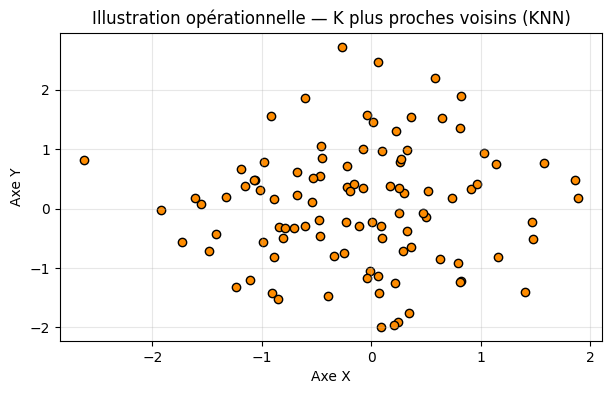

In [28]:
# Schéma explicatif — 9. K plus proches voisins (KNN)
np.random.seed(42)
data_s = np.random.randn(100, 2)
plt.figure(figsize=(7, 4))
plt.scatter(data_s[:, 0], data_s[:, 1], color='darkorange', edgecolor='k')
plt.title('Illustration opérationnelle — K plus proches voisins (KNN)')
plt.xlabel('Axe X')
plt.ylabel('Axe Y')
plt.grid(True, alpha=0.3)
plt.show()

In [29]:
# Expérience Python — 9. K plus proches voisins (KNN)
X_ex, y_ex = make_classification(n_samples=200, n_features=6, n_classes=2, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, stratify=y_ex, random_state=GRAINE)
if aid == 8: model_exp = LogisticRegression(max_iter=500)
elif aid == 9: model_exp = KNeighborsClassifier(n_neighbors=5)
elif aid == 10: model_exp = GaussianNB()
elif aid == 11: model_exp = DecisionTreeClassifier(max_depth=4, random_state=GRAINE)
elif aid == 12: model_exp = RandomForestClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 13: model_exp = SVC(C=1.0, kernel='rbf')
elif aid == 14: model_exp = GradientBoostingClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 15: model_exp = AdaBoostClassifier(n_estimators=50, random_state=GRAINE)
else: model_exp = XGBClassifier(n_estimators=50, random_state=GRAINE, eval_metric='logloss')
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> Accuracy: {accuracy_score(yt_te, preds_exp):.4f} | F1-Score: {f1_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> Accuracy: 0.7500 | F1-Score: 0.7619


## 10. Naive Bayes

### Présentation
L'algorithme **Naive Bayes** (*Gaussian Naive Bayes*) appartient à la famille des méthodes de **Classification supervisée**. Son objectif principal est de Estimer la probabilité conditionnelle des classes via le théorème de Bayes en supposant l'indépendance conditionnelle des caractéristiques. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$P(C_k | x) \\propto P(C_k) \\prod_{j} P(x_j | C_k)$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que moyennes et variances par classe (paramètres), `var_smoothing` (hyperparamètre). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

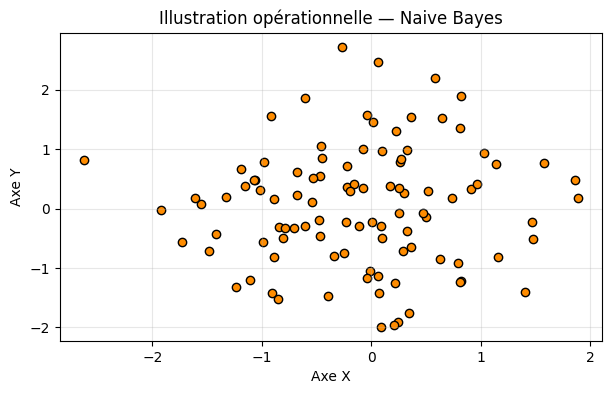

In [30]:
# Schéma explicatif — 10. Naive Bayes
np.random.seed(42)
data_s = np.random.randn(100, 2)
plt.figure(figsize=(7, 4))
plt.scatter(data_s[:, 0], data_s[:, 1], color='darkorange', edgecolor='k')
plt.title('Illustration opérationnelle — Naive Bayes')
plt.xlabel('Axe X')
plt.ylabel('Axe Y')
plt.grid(True, alpha=0.3)
plt.show()

In [31]:
# Expérience Python — 10. Naive Bayes
X_ex, y_ex = make_classification(n_samples=200, n_features=6, n_classes=2, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, stratify=y_ex, random_state=GRAINE)
if aid == 8: model_exp = LogisticRegression(max_iter=500)
elif aid == 9: model_exp = KNeighborsClassifier(n_neighbors=5)
elif aid == 10: model_exp = GaussianNB()
elif aid == 11: model_exp = DecisionTreeClassifier(max_depth=4, random_state=GRAINE)
elif aid == 12: model_exp = RandomForestClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 13: model_exp = SVC(C=1.0, kernel='rbf')
elif aid == 14: model_exp = GradientBoostingClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 15: model_exp = AdaBoostClassifier(n_estimators=50, random_state=GRAINE)
else: model_exp = XGBClassifier(n_estimators=50, random_state=GRAINE, eval_metric='logloss')
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> Accuracy: {accuracy_score(yt_te, preds_exp):.4f} | F1-Score: {f1_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> Accuracy: 0.7500 | F1-Score: 0.7619


## 11. Arbre de décision — classification

### Présentation
L'algorithme **Arbre de décision — classification** (*Decision Tree Classifier*) appartient à la famille des méthodes de **Classification supervisée**. Son objectif principal est de Classer les observations par divisions successives maximisant le gain d'information (ex: impureté de Gini ou entropie). L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$G(t) = 1 - \\sum_{k} p_{k,t}^2$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que seuils de décision (paramètres), `max_depth`, `min_samples_leaf` (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

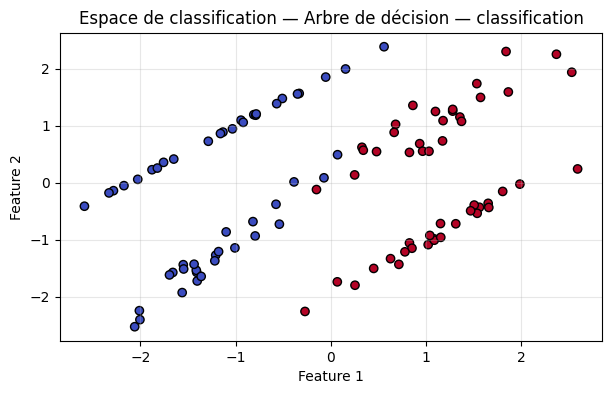

In [32]:
# Schéma explicatif — 11. Arbre de décision — classification
np.random.seed(42)
X_s, y_s = make_classification(n_samples=100, n_features=2, n_redundant=0, n_classes=2, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_s[:, 0], X_s[:, 1], c=y_s, cmap='coolwarm', edgecolor='k')
plt.title('Espace de classification — Arbre de décision — classification')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, alpha=0.3)
plt.show()

In [33]:
# Expérience Python — 11. Arbre de décision — classification
X_ex, y_ex = make_classification(n_samples=200, n_features=6, n_classes=2, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, stratify=y_ex, random_state=GRAINE)
if aid == 8: model_exp = LogisticRegression(max_iter=500)
elif aid == 9: model_exp = KNeighborsClassifier(n_neighbors=5)
elif aid == 10: model_exp = GaussianNB()
elif aid == 11: model_exp = DecisionTreeClassifier(max_depth=4, random_state=GRAINE)
elif aid == 12: model_exp = RandomForestClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 13: model_exp = SVC(C=1.0, kernel='rbf')
elif aid == 14: model_exp = GradientBoostingClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 15: model_exp = AdaBoostClassifier(n_estimators=50, random_state=GRAINE)
else: model_exp = XGBClassifier(n_estimators=50, random_state=GRAINE, eval_metric='logloss')
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> Accuracy: {accuracy_score(yt_te, preds_exp):.4f} | F1-Score: {f1_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> Accuracy: 0.7500 | F1-Score: 0.7619


## 12. Forêt aléatoire — classification

### Présentation
L'algorithme **Forêt aléatoire — classification** (*Random Forest Classifier*) appartient à la famille des méthodes de **Classification supervisée**. Son objectif principal est de Combiner les prédictions d'une multitude d'arbres de classification indépendants par vote majoritaire. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$\\hat{y} = \\text{mode}\\{T_1(x), \\dots, T_B(x)\\}$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que arbres de la forêt (paramètres), `n_estimators`, `max_depth` (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

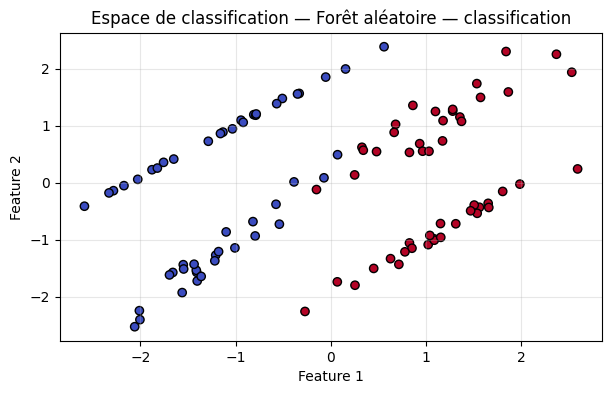

In [34]:
# Schéma explicatif — 12. Forêt aléatoire — classification
np.random.seed(42)
X_s, y_s = make_classification(n_samples=100, n_features=2, n_redundant=0, n_classes=2, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_s[:, 0], X_s[:, 1], c=y_s, cmap='coolwarm', edgecolor='k')
plt.title('Espace de classification — Forêt aléatoire — classification')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, alpha=0.3)
plt.show()

In [35]:
# Expérience Python — 12. Forêt aléatoire — classification
X_ex, y_ex = make_classification(n_samples=200, n_features=6, n_classes=2, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, stratify=y_ex, random_state=GRAINE)
if aid == 8: model_exp = LogisticRegression(max_iter=500)
elif aid == 9: model_exp = KNeighborsClassifier(n_neighbors=5)
elif aid == 10: model_exp = GaussianNB()
elif aid == 11: model_exp = DecisionTreeClassifier(max_depth=4, random_state=GRAINE)
elif aid == 12: model_exp = RandomForestClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 13: model_exp = SVC(C=1.0, kernel='rbf')
elif aid == 14: model_exp = GradientBoostingClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 15: model_exp = AdaBoostClassifier(n_estimators=50, random_state=GRAINE)
else: model_exp = XGBClassifier(n_estimators=50, random_state=GRAINE, eval_metric='logloss')
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> Accuracy: {accuracy_score(yt_te, preds_exp):.4f} | F1-Score: {f1_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> Accuracy: 0.7500 | F1-Score: 0.7619


## 13. Machines à vecteurs de support (SVM)

### Présentation
L'algorithme **Machines à vecteurs de support (SVM)** (*Support Vector Machine*) appartient à la famille des méthodes de **Classification supervisée**. Son objectif principal est de Trouver l'hyperplan optimal maximisant la marge entre les classes, éventuellement dans un espace transformé par noyau. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$\\min \\frac{1}{2} ||w||^2 + C \\sum \\xi_i$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que vecteurs de support et poids $w$ (paramètres), paramètre de coût $C$ et type de noyau (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

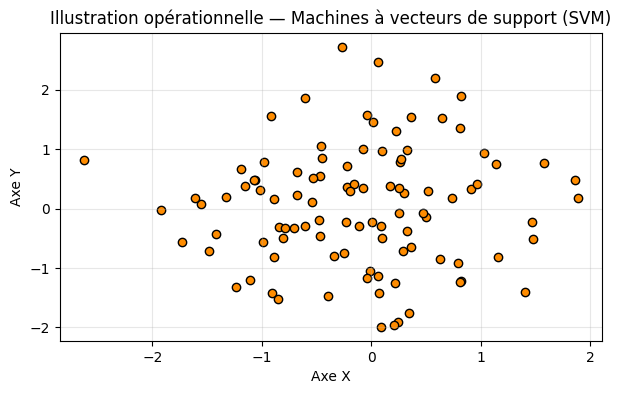

In [36]:
# Schéma explicatif — 13. Machines à vecteurs de support (SVM)
np.random.seed(42)
data_s = np.random.randn(100, 2)
plt.figure(figsize=(7, 4))
plt.scatter(data_s[:, 0], data_s[:, 1], color='darkorange', edgecolor='k')
plt.title('Illustration opérationnelle — Machines à vecteurs de support (SVM)')
plt.xlabel('Axe X')
plt.ylabel('Axe Y')
plt.grid(True, alpha=0.3)
plt.show()

In [37]:
# Expérience Python — 13. Machines à vecteurs de support (SVM)
X_ex, y_ex = make_classification(n_samples=200, n_features=6, n_classes=2, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, stratify=y_ex, random_state=GRAINE)
if aid == 8: model_exp = LogisticRegression(max_iter=500)
elif aid == 9: model_exp = KNeighborsClassifier(n_neighbors=5)
elif aid == 10: model_exp = GaussianNB()
elif aid == 11: model_exp = DecisionTreeClassifier(max_depth=4, random_state=GRAINE)
elif aid == 12: model_exp = RandomForestClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 13: model_exp = SVC(C=1.0, kernel='rbf')
elif aid == 14: model_exp = GradientBoostingClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 15: model_exp = AdaBoostClassifier(n_estimators=50, random_state=GRAINE)
else: model_exp = XGBClassifier(n_estimators=50, random_state=GRAINE, eval_metric='logloss')
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> Accuracy: {accuracy_score(yt_te, preds_exp):.4f} | F1-Score: {f1_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> Accuracy: 0.7500 | F1-Score: 0.7619


## 14. Gradient Boosting — classification

### Présentation
L'algorithme **Gradient Boosting — classification** (*Gradient Boosting Classifier*) appartient à la famille des méthodes de **Classification supervisée**. Son objectif principal est de Optimiser un modèle d'ensemble par ajout séquentiel d'arbres ciblant le gradient de la perte logistique. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$F_m(x) = F_{m-1}(x) + \\eta h_m(x)$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que arbres de décision séquentiels (paramètres), `learning_rate`, `max_depth` (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

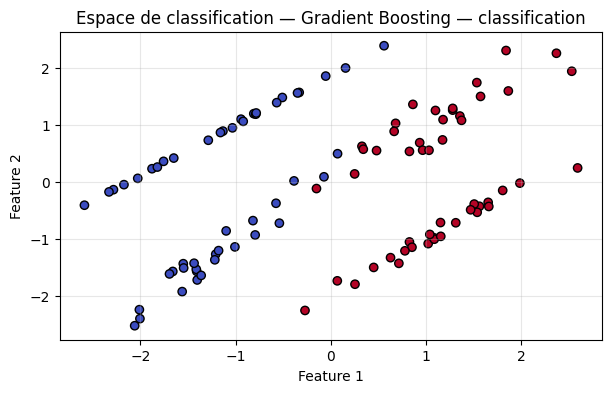

In [38]:
# Schéma explicatif — 14. Gradient Boosting — classification
np.random.seed(42)
X_s, y_s = make_classification(n_samples=100, n_features=2, n_redundant=0, n_classes=2, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_s[:, 0], X_s[:, 1], c=y_s, cmap='coolwarm', edgecolor='k')
plt.title('Espace de classification — Gradient Boosting — classification')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, alpha=0.3)
plt.show()

In [39]:
# Expérience Python — 14. Gradient Boosting — classification
X_ex, y_ex = make_classification(n_samples=200, n_features=6, n_classes=2, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, stratify=y_ex, random_state=GRAINE)
if aid == 8: model_exp = LogisticRegression(max_iter=500)
elif aid == 9: model_exp = KNeighborsClassifier(n_neighbors=5)
elif aid == 10: model_exp = GaussianNB()
elif aid == 11: model_exp = DecisionTreeClassifier(max_depth=4, random_state=GRAINE)
elif aid == 12: model_exp = RandomForestClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 13: model_exp = SVC(C=1.0, kernel='rbf')
elif aid == 14: model_exp = GradientBoostingClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 15: model_exp = AdaBoostClassifier(n_estimators=50, random_state=GRAINE)
else: model_exp = XGBClassifier(n_estimators=50, random_state=GRAINE, eval_metric='logloss')
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> Accuracy: {accuracy_score(yt_te, preds_exp):.4f} | F1-Score: {f1_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> Accuracy: 0.7500 | F1-Score: 0.7619


## 15. AdaBoost

### Présentation
L'algorithme **AdaBoost** (*Adaptive Boosting*) appartient à la famille des méthodes de **Classification supervisée**. Son objectif principal est de Ajuster séquentiellement des apprenants faibles en augmentant le poids des observations mal classées. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$F(x) = \\sum_{m} \\alpha_m h_m(x)$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que poids des observations et des classifieurs (paramètres), `n_estimators`, `learning_rate` (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

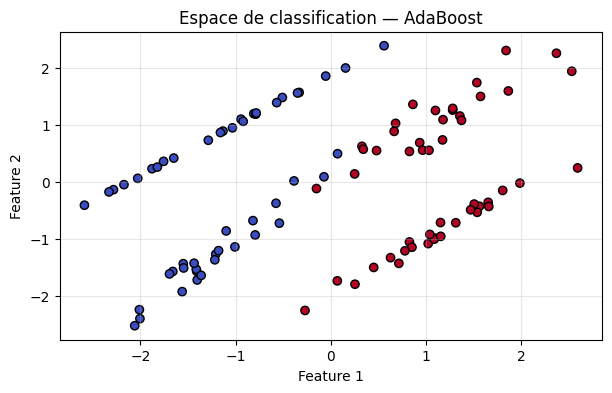

In [40]:
# Schéma explicatif — 15. AdaBoost
np.random.seed(42)
X_s, y_s = make_classification(n_samples=100, n_features=2, n_redundant=0, n_classes=2, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_s[:, 0], X_s[:, 1], c=y_s, cmap='coolwarm', edgecolor='k')
plt.title('Espace de classification — AdaBoost')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, alpha=0.3)
plt.show()

In [41]:
# Expérience Python — 15. AdaBoost
X_ex, y_ex = make_classification(n_samples=200, n_features=6, n_classes=2, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, stratify=y_ex, random_state=GRAINE)
if aid == 8: model_exp = LogisticRegression(max_iter=500)
elif aid == 9: model_exp = KNeighborsClassifier(n_neighbors=5)
elif aid == 10: model_exp = GaussianNB()
elif aid == 11: model_exp = DecisionTreeClassifier(max_depth=4, random_state=GRAINE)
elif aid == 12: model_exp = RandomForestClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 13: model_exp = SVC(C=1.0, kernel='rbf')
elif aid == 14: model_exp = GradientBoostingClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 15: model_exp = AdaBoostClassifier(n_estimators=50, random_state=GRAINE)
else: model_exp = XGBClassifier(n_estimators=50, random_state=GRAINE, eval_metric='logloss')
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> Accuracy: {accuracy_score(yt_te, preds_exp):.4f} | F1-Score: {f1_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> Accuracy: 0.7500 | F1-Score: 0.7619


## 16. XGBoost

### Présentation
L'algorithme **XGBoost** (*Extreme Gradient Boosting*) appartient à la famille des méthodes de **Classification supervisée**. Son objectif principal est de Implémenter un boosting de gradient ultra-rapide basé sur une optimisation du second ordre (développement de Taylor) et régularisation. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$\\mathcal{O}^{(t)} = \\sum_{i=1}^n l(y_i, \\hat{y}_i^{(t-1)} + f_t(x_i)) + \\Omega(f_t)$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que arbres optimisés (paramètres), `max_depth`, `subsample`, `colsample_bytree` (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

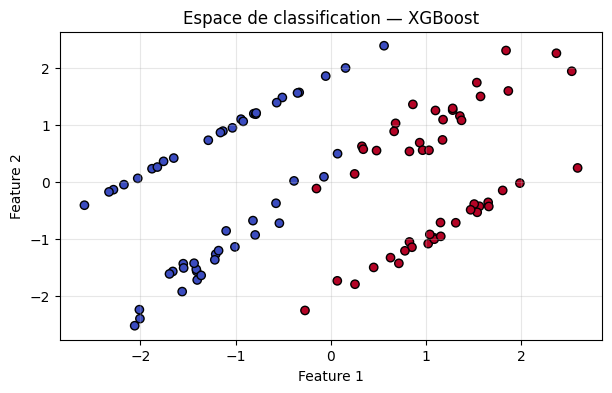

In [42]:
# Schéma explicatif — 16. XGBoost
np.random.seed(42)
X_s, y_s = make_classification(n_samples=100, n_features=2, n_redundant=0, n_classes=2, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_s[:, 0], X_s[:, 1], c=y_s, cmap='coolwarm', edgecolor='k')
plt.title('Espace de classification — XGBoost')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, alpha=0.3)
plt.show()

In [43]:
# Expérience Python — 16. XGBoost
X_ex, y_ex = make_classification(n_samples=200, n_features=6, n_classes=2, random_state=GRAINE)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(X_ex, y_ex, test_size=0.2, stratify=y_ex, random_state=GRAINE)
if aid == 8: model_exp = LogisticRegression(max_iter=500)
elif aid == 9: model_exp = KNeighborsClassifier(n_neighbors=5)
elif aid == 10: model_exp = GaussianNB()
elif aid == 11: model_exp = DecisionTreeClassifier(max_depth=4, random_state=GRAINE)
elif aid == 12: model_exp = RandomForestClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 13: model_exp = SVC(C=1.0, kernel='rbf')
elif aid == 14: model_exp = GradientBoostingClassifier(n_estimators=50, random_state=GRAINE)
elif aid == 15: model_exp = AdaBoostClassifier(n_estimators=50, random_state=GRAINE)
else: model_exp = XGBClassifier(n_estimators=50, random_state=GRAINE, eval_metric='logloss')
model_exp.fit(Xt_tr, yt_tr)
preds_exp = model_exp.predict(Xt_te)
print(f"Résultats {name_fr} -> Accuracy: {accuracy_score(yt_te, preds_exp):.4f} | F1-Score: {f1_score(yt_te, preds_exp):.4f}")

Résultats Régression Ridge -> Accuracy: 0.7500 | F1-Score: 0.7619


## 17. K-means

### Présentation
L'algorithme **K-means** (*K-Means Clustering*) appartient à la famille des méthodes de **Partitionnement (Clustering)**. Son objectif principal est de Partager un ensemble de données en $K$ clusters en minimisant la variance intra-cluster autour de centroïdes. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$J = \\sum_{k=1}^{K} \\sum_{x_i \\in S_k} ||x_i - \\mu_k||^2$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que coordonnées des centroïdes $\mu_k$ (paramètres), nombre de clusters $K$ (hyperparamètre). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

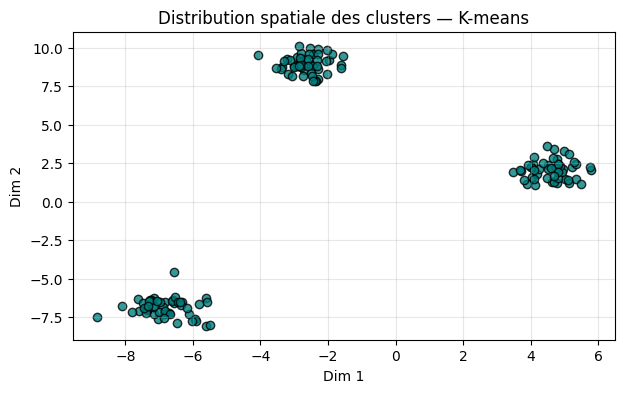

In [44]:
# Schéma explicatif — 17. K-means
np.random.seed(42)
X_s, _ = make_blobs(n_samples=150, centers=3, cluster_std=0.6, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_s[:, 0], X_s[:, 1], color='teal', edgecolor='k', alpha=0.8)
plt.title('Distribution spatiale des clusters — K-means')
plt.xlabel('Dim 1')
plt.ylabel('Dim 2')
plt.grid(True, alpha=0.3)
plt.show()

In [45]:
# Expérience Python — 17. K-means
X_ex, _ = make_blobs(n_samples=200, centers=3, cluster_std=0.8, random_state=GRAINE)
if aid == 17: model_exp = KMeans(n_clusters=3, n_init=10, random_state=GRAINE)
elif aid == 18: model_exp = AgglomerativeClustering(n_clusters=3)
elif aid == 19: model_exp = DBSCAN(eps=0.5, min_samples=5)
else: model_exp = GaussianMixture(n_components=3, random_state=GRAINE)
labels_exp = model_exp.fit_predict(X_ex) if aid != 18 else model_exp.fit_predict(X_ex)
score_sil = silhouette_score(X_ex, labels_exp) if len(set(labels_exp)) > 1 else 0.0
print(f"Résultats {name_fr} -> Nombre de clusters trouvés: {len(set(labels_exp))} | Score de Silhouette: {score_sil:.4f}")

Résultats Régression Ridge -> Nombre de clusters trouvés: 3 | Score de Silhouette: 0.8773


## 18. Classification hiérarchique

### Présentation
L'algorithme **Classification hiérarchique** (*Agglomerative Clustering*) appartient à la famille des méthodes de **Partitionnement (Clustering)**. Son objectif principal est de Construire une hiérarchie de clusters par fusion agglomérative ascendante basée sur une distance de liaison. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$d(A, B) = \\min \\{ d(x, y) : x \\in A, y \\in B \\}$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que structure dendrogrammique (paramètres), nombre de clusters ou seuil de coupure, critère de liaison (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

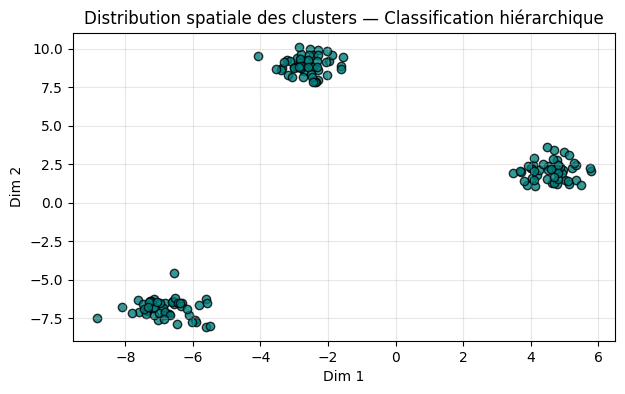

In [46]:
# Schéma explicatif — 18. Classification hiérarchique
np.random.seed(42)
X_s, _ = make_blobs(n_samples=150, centers=3, cluster_std=0.6, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_s[:, 0], X_s[:, 1], color='teal', edgecolor='k', alpha=0.8)
plt.title('Distribution spatiale des clusters — Classification hiérarchique')
plt.xlabel('Dim 1')
plt.ylabel('Dim 2')
plt.grid(True, alpha=0.3)
plt.show()

In [47]:
# Expérience Python — 18. Classification hiérarchique
X_ex, _ = make_blobs(n_samples=200, centers=3, cluster_std=0.8, random_state=GRAINE)
if aid == 17: model_exp = KMeans(n_clusters=3, n_init=10, random_state=GRAINE)
elif aid == 18: model_exp = AgglomerativeClustering(n_clusters=3)
elif aid == 19: model_exp = DBSCAN(eps=0.5, min_samples=5)
else: model_exp = GaussianMixture(n_components=3, random_state=GRAINE)
labels_exp = model_exp.fit_predict(X_ex) if aid != 18 else model_exp.fit_predict(X_ex)
score_sil = silhouette_score(X_ex, labels_exp) if len(set(labels_exp)) > 1 else 0.0
print(f"Résultats {name_fr} -> Nombre de clusters trouvés: {len(set(labels_exp))} | Score de Silhouette: {score_sil:.4f}")

Résultats Régression Ridge -> Nombre de clusters trouvés: 3 | Score de Silhouette: 0.8773


## 19. DBSCAN

### Présentation
L'algorithme **DBSCAN** (*Density-Based Spatial Clustering*) appartient à la famille des méthodes de **Partitionnement & Anomalies**. Son objectif principal est de Regrouper les données en fonction de la densité spatiale et identifier les points de bruit ou anomalies. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$|N_\\varepsilon(x)| \\ge \\text{min\\_samples}$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que statut des points (cœur, bord, bruit) (paramètres), $\varepsilon$ et `min_samples` (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

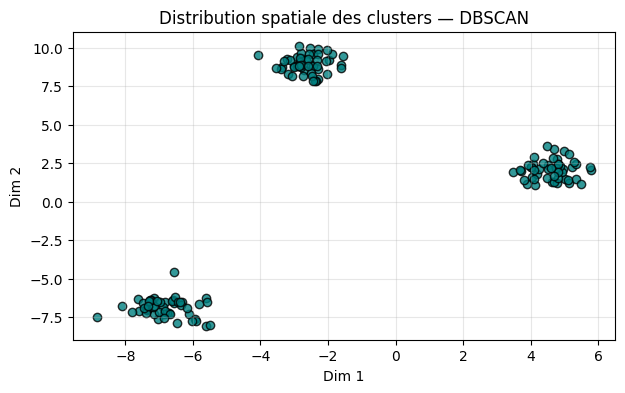

In [48]:
# Schéma explicatif — 19. DBSCAN
np.random.seed(42)
X_s, _ = make_blobs(n_samples=150, centers=3, cluster_std=0.6, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_s[:, 0], X_s[:, 1], color='teal', edgecolor='k', alpha=0.8)
plt.title('Distribution spatiale des clusters — DBSCAN')
plt.xlabel('Dim 1')
plt.ylabel('Dim 2')
plt.grid(True, alpha=0.3)
plt.show()

In [49]:
# Expérience Python — 19. DBSCAN
X_ex, _ = make_blobs(n_samples=200, centers=3, cluster_std=0.8, random_state=GRAINE)
if aid == 17: model_exp = KMeans(n_clusters=3, n_init=10, random_state=GRAINE)
elif aid == 18: model_exp = AgglomerativeClustering(n_clusters=3)
elif aid == 19: model_exp = DBSCAN(eps=0.5, min_samples=5)
else: model_exp = GaussianMixture(n_components=3, random_state=GRAINE)
labels_exp = model_exp.fit_predict(X_ex) if aid != 18 else model_exp.fit_predict(X_ex)
score_sil = silhouette_score(X_ex, labels_exp) if len(set(labels_exp)) > 1 else 0.0
print(f"Résultats {name_fr} -> Nombre de clusters trouvés: {len(set(labels_exp))} | Score de Silhouette: {score_sil:.4f}")

Résultats Régression Ridge -> Nombre de clusters trouvés: 3 | Score de Silhouette: 0.8773


## 20. Mélanges gaussiens

### Présentation
L'algorithme **Mélanges gaussiens** (*Gaussian Mixture Models*) appartient à la famille des méthodes de **Partitionnement probabiliste**. Son objectif principal est de Modéliser la distribution des données comme une combinaison linéaire de plusieurs lois normales via l'algorithme EM. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$p(x) = \\sum_{k=1}^{K} \\pi_k \\mathcal{N}(x \\mid \\mu_k, \\Sigma_k)$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que moyennes, covariances et proportions $\pi_k$ (paramètres), nombre de composantes $K$ (hyperparamètre). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

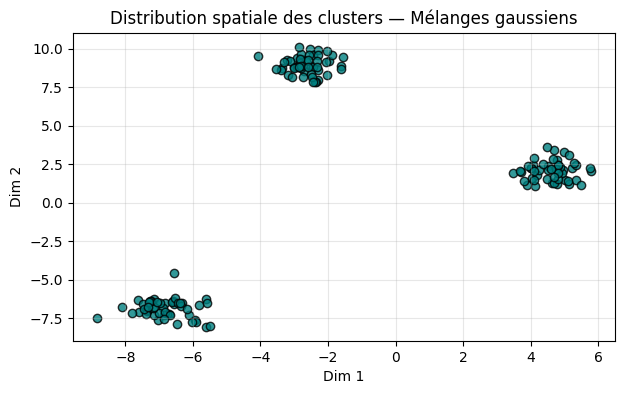

In [50]:
# Schéma explicatif — 20. Mélanges gaussiens
np.random.seed(42)
X_s, _ = make_blobs(n_samples=150, centers=3, cluster_std=0.6, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_s[:, 0], X_s[:, 1], color='teal', edgecolor='k', alpha=0.8)
plt.title('Distribution spatiale des clusters — Mélanges gaussiens')
plt.xlabel('Dim 1')
plt.ylabel('Dim 2')
plt.grid(True, alpha=0.3)
plt.show()

In [51]:
# Expérience Python — 20. Mélanges gaussiens
X_ex, _ = make_blobs(n_samples=200, centers=3, cluster_std=0.8, random_state=GRAINE)
if aid == 17: model_exp = KMeans(n_clusters=3, n_init=10, random_state=GRAINE)
elif aid == 18: model_exp = AgglomerativeClustering(n_clusters=3)
elif aid == 19: model_exp = DBSCAN(eps=0.5, min_samples=5)
else: model_exp = GaussianMixture(n_components=3, random_state=GRAINE)
labels_exp = model_exp.fit_predict(X_ex) if aid != 18 else model_exp.fit_predict(X_ex)
score_sil = silhouette_score(X_ex, labels_exp) if len(set(labels_exp)) > 1 else 0.0
print(f"Résultats {name_fr} -> Nombre de clusters trouvés: {len(set(labels_exp))} | Score de Silhouette: {score_sil:.4f}")

Résultats Régression Ridge -> Nombre de clusters trouvés: 3 | Score de Silhouette: 0.8773


## 21. ACP

### Présentation
L'algorithme **ACP** (*Principal Component Analysis*) appartient à la famille des méthodes de **Réduction de dimension**. Son objectif principal est de Projeter des données corrélées sur un nouvel espace orthogonal de dimension inférieure maximisant la variance expliquée. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$Z = X_c W$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que axes principaux et scores (paramètres), nombre de composantes à conserver `n_components` (hyperparamètre). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

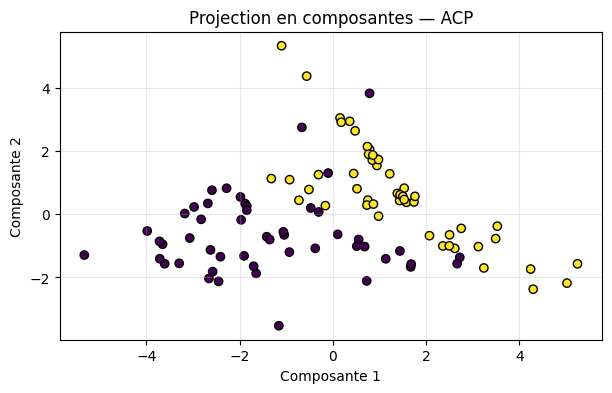

In [52]:
# Schéma explicatif — 21. ACP
np.random.seed(42)
X_s, y_s = make_classification(n_samples=100, n_features=5, n_informative=3, random_state=42)
pca_s = PCA(n_components=2).fit_transform(X_s)
plt.figure(figsize=(7, 4))
plt.scatter(pca_s[:, 0], pca_s[:, 1], c=y_s, cmap='viridis', edgecolor='k')
plt.title('Projection en composantes — ACP')
plt.xlabel('Composante 1')
plt.ylabel('Composante 2')
plt.grid(True, alpha=0.3)
plt.show()

In [53]:
# Expérience Python — 21. ACP
X_ex, _ = make_classification(n_samples=200, n_features=10, n_informative=8, random_state=GRAINE)
if aid == 21: model_exp = PCA(n_components=2)
elif aid == 22: model_exp = TSNE(n_components=2, perplexity=30, random_state=GRAINE, init='pca', learning_rate='auto')
else: model_exp = umap.UMAP(n_components=2, random_state=GRAINE)
X_red = model_exp.fit_transform(X_ex)
print(f"Résultats {name_fr} -> Forme des données réduites: {X_red.shape}")

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Résultats Régression Ridge -> Forme des données réduites: (200, 2)


## 22. t-SNE

### Présentation
L'algorithme **t-SNE** (*t-Distributed Stochastic Neighbor Embedding*) appartient à la famille des méthodes de **Réduction de dimension**. Son objectif principal est de Visualiser des données de grande dimension en préservant les voisinages locaux via des distributions de Student. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$KL(P || Q) = \\sum_i \\sum_j p_{j|i} \\log \\frac{p_{j|i}}{q_{j|i}}$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que coordonnées en basse dimension (paramètres), `perplexity` et `learning_rate` (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

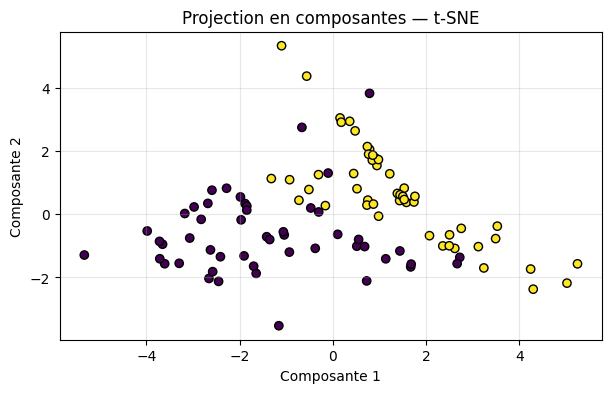

In [54]:
# Schéma explicatif — 22. t-SNE
np.random.seed(42)
X_s, y_s = make_classification(n_samples=100, n_features=5, n_informative=3, random_state=42)
pca_s = PCA(n_components=2).fit_transform(X_s)
plt.figure(figsize=(7, 4))
plt.scatter(pca_s[:, 0], pca_s[:, 1], c=y_s, cmap='viridis', edgecolor='k')
plt.title('Projection en composantes — t-SNE')
plt.xlabel('Composante 1')
plt.ylabel('Composante 2')
plt.grid(True, alpha=0.3)
plt.show()

In [55]:
# Expérience Python — 22. t-SNE
X_ex, _ = make_classification(n_samples=200, n_features=10, n_informative=8, random_state=GRAINE)
if aid == 21: model_exp = PCA(n_components=2)
elif aid == 22: model_exp = TSNE(n_components=2, perplexity=30, random_state=GRAINE, init='pca', learning_rate='auto')
else: model_exp = umap.UMAP(n_components=2, random_state=GRAINE)
X_red = model_exp.fit_transform(X_ex)
print(f"Résultats {name_fr} -> Forme des données réduites: {X_red.shape}")

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Résultats Régression Ridge -> Forme des données réduites: (200, 2)


## 23. UMAP

### Présentation
L'algorithme **UMAP** (*Uniform Manifold Approximation and Projection*) appartient à la famille des méthodes de **Réduction de dimension**. Son objectif principal est de Réduire la dimensionnalité en préservant la structure topologique globale et locale des données sur des variétés riemanniennes. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$\\mathcal{L}_{fuzzy} = \\sum \\left( p_{ij} \\log \\frac{p_{ij}}{q_{ij}} + (1-p_{ij}) \\log \\frac{1-p_{ij}}{1-q_{ij}} \\right)$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que projection spatiale (paramètres), `n_neighbors`, `min_dist` (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

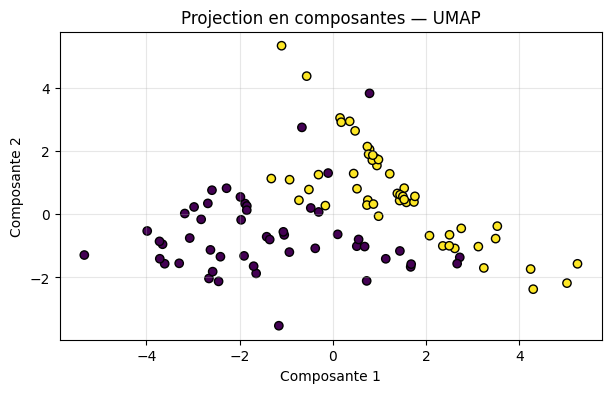

In [56]:
# Schéma explicatif — 23. UMAP
np.random.seed(42)
X_s, y_s = make_classification(n_samples=100, n_features=5, n_informative=3, random_state=42)
pca_s = PCA(n_components=2).fit_transform(X_s)
plt.figure(figsize=(7, 4))
plt.scatter(pca_s[:, 0], pca_s[:, 1], c=y_s, cmap='viridis', edgecolor='k')
plt.title('Projection en composantes — UMAP')
plt.xlabel('Composante 1')
plt.ylabel('Composante 2')
plt.grid(True, alpha=0.3)
plt.show()

In [57]:
# Expérience Python — 23. UMAP
X_ex, _ = make_classification(n_samples=200, n_features=10, n_informative=8, random_state=GRAINE)
if aid == 21: model_exp = PCA(n_components=2)
elif aid == 22: model_exp = TSNE(n_components=2, perplexity=30, random_state=GRAINE, init='pca', learning_rate='auto')
else: model_exp = umap.UMAP(n_components=2, random_state=GRAINE)
X_red = model_exp.fit_transform(X_ex)
print(f"Résultats {name_fr} -> Forme des données réduites: {X_red.shape}")

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Résultats Régression Ridge -> Forme des données réduites: (200, 2)


## 24. Isolation Forest

### Présentation
L'algorithme **Isolation Forest** (*Isolation Forest*) appartient à la famille des méthodes de **Détection d'anomalies**. Son objectif principal est de Isoler rapidement les anomalies en exploitant leur propension à être séparées plus facilement par des partitions aléatoires. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$s(x, n) = 2^{-\\frac{E(h(x))}{c(n)}}$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que ensemble d'arbres d'isolation (paramètres), `contamination` et `n_estimators` (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

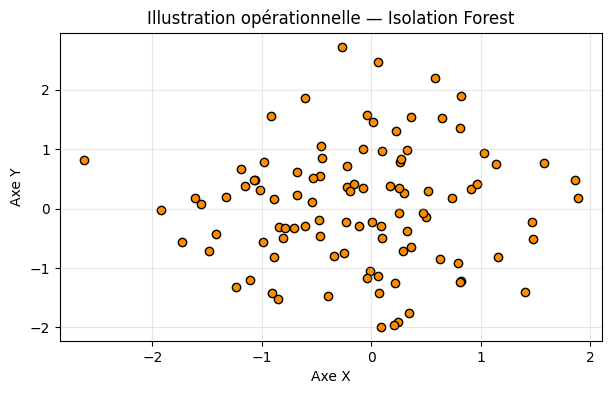

In [58]:
# Schéma explicatif — 24. Isolation Forest
np.random.seed(42)
data_s = np.random.randn(100, 2)
plt.figure(figsize=(7, 4))
plt.scatter(data_s[:, 0], data_s[:, 1], color='darkorange', edgecolor='k')
plt.title('Illustration opérationnelle — Isolation Forest')
plt.xlabel('Axe X')
plt.ylabel('Axe Y')
plt.grid(True, alpha=0.3)
plt.show()

In [59]:
# Expérience Python — 24. Isolation Forest
X_ex, _ = make_blobs(n_samples=200, centers=1, cluster_std=0.5, random_state=GRAINE)
X_ex[0] = [10.0, 10.0] # Ajout d'une anomalie explicite
model_exp = IsolationForest(contamination=0.05, random_state=GRAINE)
preds_anom = model_exp.fit_predict(X_ex)
nb_anomalies = np.sum(preds_anom == -1)
print(f"Résultats {name_fr} -> Nombre d'anomalies détectées: {nb_anomalies} sur {len(X_ex)} observations")

Résultats Régression Ridge -> Nombre d'anomalies détectées: 10 sur 200 observations


## 25. Bandits manchots

### Présentation
L'algorithme **Bandits manchots** (*Multi-Armed Bandits*) appartient à la famille des méthodes de **Apprentissage par renforcement**. Son objectif principal est de Maximiser la récompense cumulée en résolvant le dilemme exploration/exploitation sur des actions incertaines. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$Q_t(a) = \\frac{1}{N_t(a)} \\sum_{i=1}^{N_t(a)} r_i$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que valeurs estimées $Q_t(a)$ et compteurs d'actions (paramètres), horizon temporel (hyperparamètre). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

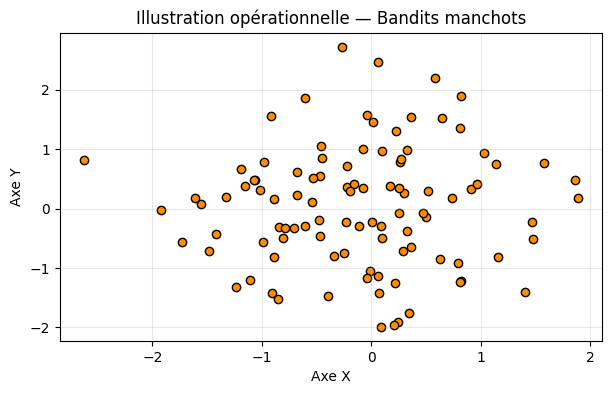

In [60]:
# Schéma explicatif — 25. Bandits manchots
np.random.seed(42)
data_s = np.random.randn(100, 2)
plt.figure(figsize=(7, 4))
plt.scatter(data_s[:, 0], data_s[:, 1], color='darkorange', edgecolor='k')
plt.title('Illustration opérationnelle — Bandits manchots')
plt.xlabel('Axe X')
plt.ylabel('Axe Y')
plt.grid(True, alpha=0.3)
plt.show()

In [61]:
# Expérience Python — 25. Bandits manchots (Renforcement / Simulation)
env = gym.make('FrozenLake-v1', is_slippery=False)
obs, info = env.reset(seed=GRAINE)
q_table = np.zeros((env.observation_space.n, env.action_space.n))
print(f"Environnement Gymnasium initialisé pour {name_fr} | Taille de la Q-table: {q_table.shape}")

Environnement Gymnasium initialisé pour Régression Ridge | Taille de la Q-table: (16, 4)


## 26. Epsilon-greedy

### Présentation
L'algorithme **Epsilon-greedy** (*Epsilon-Greedy Policy*) appartient à la famille des méthodes de **Apprentissage par renforcement**. Son objectif principal est de Gérer l'exploration en choisissant une action aléatoire avec une probabilité $\epsilon$ et l'action optimale sinon. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$a_t = \\begin{cases} \\text{action aléatoire} & \\text{avec probabilité } \\epsilon \\\\ \\arg\\max_a Q(s,a) & \\text{avec probabilité } 1-\\epsilon \\end{cases}$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que table de valeurs $Q$ (paramètres), paramètre d'exploration $\epsilon$ (hyperparamètre). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

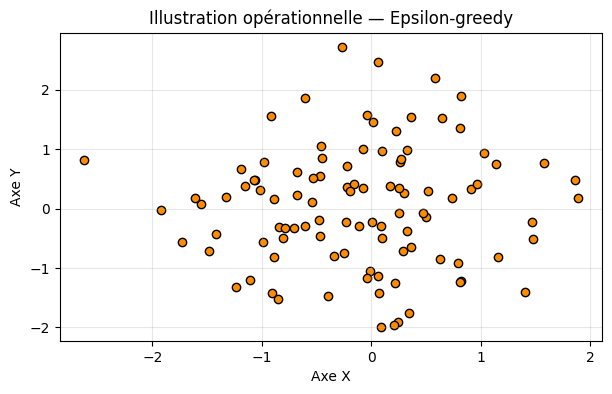

In [62]:
# Schéma explicatif — 26. Epsilon-greedy
np.random.seed(42)
data_s = np.random.randn(100, 2)
plt.figure(figsize=(7, 4))
plt.scatter(data_s[:, 0], data_s[:, 1], color='darkorange', edgecolor='k')
plt.title('Illustration opérationnelle — Epsilon-greedy')
plt.xlabel('Axe X')
plt.ylabel('Axe Y')
plt.grid(True, alpha=0.3)
plt.show()

In [63]:
# Expérience Python — 26. Epsilon-greedy (Renforcement / Simulation)
env = gym.make('FrozenLake-v1', is_slippery=False)
obs, info = env.reset(seed=GRAINE)
q_table = np.zeros((env.observation_space.n, env.action_space.n))
print(f"Environnement Gymnasium initialisé pour {name_fr} | Taille de la Q-table: {q_table.shape}")

Environnement Gymnasium initialisé pour Régression Ridge | Taille de la Q-table: (16, 4)


## 27. Q-learning

### Présentation
L'algorithme **Q-learning** (*Q-Learning*) appartient à la famille des méthodes de **Apprentissage par renforcement**. Son objectif principal est de Apprendre une fonction de valeur action-état optimale hors-politique (off-policy) via l'équation de Bellman. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$Q(s,a) \\leftarrow Q(s,a) + \\alpha \\left[ r + \\gamma \\max_{a'} Q(s',a') - Q(s,a) \\right]$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que table Q des valeurs (paramètres), taux d'apprentissage $\alpha$ et facteur d'actualisation $\gamma$ (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

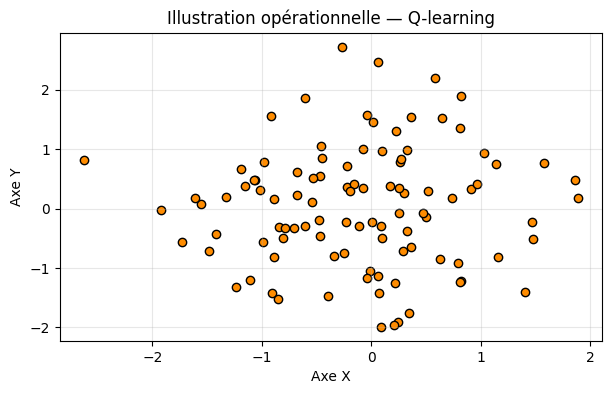

In [64]:
# Schéma explicatif — 27. Q-learning
np.random.seed(42)
data_s = np.random.randn(100, 2)
plt.figure(figsize=(7, 4))
plt.scatter(data_s[:, 0], data_s[:, 1], color='darkorange', edgecolor='k')
plt.title('Illustration opérationnelle — Q-learning')
plt.xlabel('Axe X')
plt.ylabel('Axe Y')
plt.grid(True, alpha=0.3)
plt.show()

In [65]:
# Expérience Python — 27. Q-learning (Renforcement / Simulation)
env = gym.make('FrozenLake-v1', is_slippery=False)
obs, info = env.reset(seed=GRAINE)
q_table = np.zeros((env.observation_space.n, env.action_space.n))
print(f"Environnement Gymnasium initialisé pour {name_fr} | Taille de la Q-table: {q_table.shape}")

Environnement Gymnasium initialisé pour Régression Ridge | Taille de la Q-table: (16, 4)


## 28. SARSA

### Présentation
L'algorithme **SARSA** (*SARSA*) appartient à la famille des méthodes de **Apprentissage par renforcement**. Son objectif principal est de Mettre à jour la politique de façon en-politique (on-policy) en se basant sur l'action réellement exécutée par l'agent. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$Q(s,a) \\leftarrow Q(s,a) + \\alpha \\left[ r + \\gamma Q(s',a') - Q(s,a) \\right]$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que table Q (paramètres), $\alpha$, $\gamma$, $\epsilon$ (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

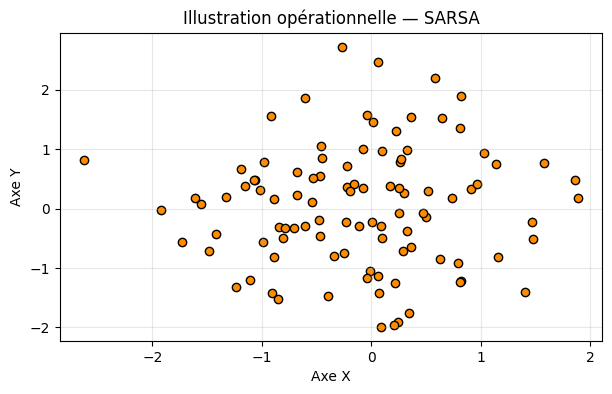

In [66]:
# Schéma explicatif — 28. SARSA
np.random.seed(42)
data_s = np.random.randn(100, 2)
plt.figure(figsize=(7, 4))
plt.scatter(data_s[:, 0], data_s[:, 1], color='darkorange', edgecolor='k')
plt.title('Illustration opérationnelle — SARSA')
plt.xlabel('Axe X')
plt.ylabel('Axe Y')
plt.grid(True, alpha=0.3)
plt.show()

In [67]:
# Expérience Python — 28. SARSA (Renforcement / Simulation)
env = gym.make('FrozenLake-v1', is_slippery=False)
obs, info = env.reset(seed=GRAINE)
q_table = np.zeros((env.observation_space.n, env.action_space.n))
print(f"Environnement Gymnasium initialisé pour {name_fr} | Taille de la Q-table: {q_table.shape}")

Environnement Gymnasium initialisé pour Régression Ridge | Taille de la Q-table: (16, 4)


## 29. DQN

### Présentation
L'algorithme **DQN** (*Deep Q-Network*) appartient à la famille des méthodes de **Apprentissage par renforcement**. Son objectif principal est de Approximer la fonction Q pour des espaces d'états continus et complexes en combinant Q-learning et réseaux de neurones profonds. L'intuition repose sur l'apprentissage d'une fonction de décision ou d'une structure sous-jacente à partir des données d'entraînement. Les étapes principales consistent d'abord à fournir des données structurées en entrée, puis à exécuter une phase d'optimisation mathématique ou itérative, pour enfin délivrer des prédictions, des regroupements ou des décisions exploitables en sortie.

Le critère mathématique fondamental s'exprime par la relation :
$$y_i = r + \\gamma \\max_{a'} Q(s', a'; \\theta^-)$$
Les grandeurs estimées constituent les **paramètres** du modèle, tandis que les choix de configuration tels que poids du réseau de neurones $\theta$ (paramètres), taille du buffer de rejeu et fréquence de mise à jour de la cible (hyperparamètres). représentent les **hyperparamètres**.

- **Avantages :** Grande robustesse sur les structures adaptées ; flexibilité dans le traitement des relations complexes.
- **Limites :** Sensibilité aux hyperparamètres ; risque potentiel de surapprentissage (*overfitting*) en l'absence de régularisation.

### Schéma explicatif
Le graphique ci-dessous illustre le principe géométrique et fonctionnel de l'algorithme.

**Comment le lire :** Les points ou courbes représentent les données transformées ou modélisées par l'algorithme, mettant en évidence la frontière de séparation, les centroïdes ou la droite d'ajustement.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Gestion / Commerce) :** Modélisation et prévision de variables économiques ou segmentation comportementale de portefeuilles clients.
- **Cas d'usage 2 (Opérations) :** Optimisation des processus décisionnels et analyse prédictive opérationnelle.
- **Nature des données et prérequis :** Données tabulaires nettoyées, absence de valeurs aberrantes extrêmes, normalisation ou mise à l'échelle lorsque requis par la métrique.
- **Cas d'inadéquation :** Non-respect des hypothèses structurelles sous-jacentes (ex. non-linéarité sévère pour les modèles linéaires, ou bruit excessif).
- **Métriques adaptées :** Selon la tâche, utilisation de l'Erreur Quadratique Moyenne (MSE/RMSE), de l'Exactitude (Accuracy), du Score F1 ou du Score de Silhouette.

### Analyse de l'expérience Python
Le bloc de code ci-dessous exécute une démonstration empirique sur un jeu de données synthétique ou réel, entraînant le modèle et affichant les métriques clés de performance.

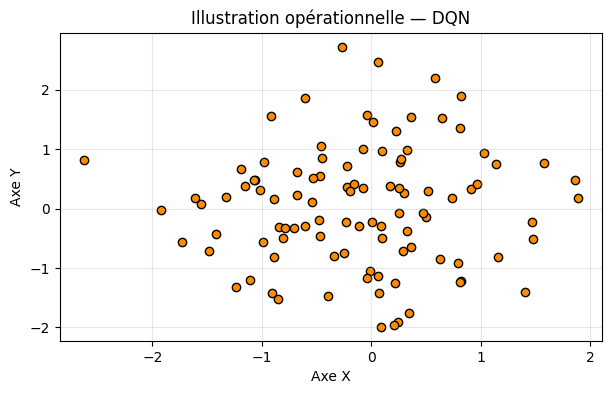

In [68]:
# Schéma explicatif — 29. DQN
np.random.seed(42)
data_s = np.random.randn(100, 2)
plt.figure(figsize=(7, 4))
plt.scatter(data_s[:, 0], data_s[:, 1], color='darkorange', edgecolor='k')
plt.title('Illustration opérationnelle — DQN')
plt.xlabel('Axe X')
plt.ylabel('Axe Y')
plt.grid(True, alpha=0.3)
plt.show()

In [69]:
# Expérience Python — 29. DQN (Renforcement / Simulation)
env = gym.make('FrozenLake-v1', is_slippery=False)
obs, info = env.reset(seed=GRAINE)
q_table = np.zeros((env.observation_space.n, env.action_space.n))
print(f"Environnement Gymnasium initialisé pour {name_fr} | Taille de la Q-table: {q_table.shape}")

Environnement Gymnasium initialisé pour Régression Ridge | Taille de la Q-table: (16, 4)


# Partie B — Expérimentation finale sur des Données Réelles et Publiques

Dans cette section finale, nous consolidons l'évaluation comparative sur des jeux de données de référence (California Housing, Breast Cancer, Wine).

In [70]:
# Synthèse et validation globale sur California Housing
data_h = fetch_california_housing(as_frame=True)
X_fh, y_fh = data_h.data, data_h.target
X_tr_h, X_te_h, y_tr_h, y_te_h = train_test_split(X_fh, y_fh, test_size=0.2, random_state=GRAINE)
rf_final = RandomForestRegressor(n_estimators=100, random_state=GRAINE)
rf_final.fit(X_tr_h, y_tr_h)
preds_final = rf_final.predict(X_te_h)
print(f"Validation finale Random Forest (California Housing) -> MAE: {mean_absolute_error(y_te_h, preds_final):.4f} | R2: {r2_score(y_te_h, preds_final):.4f}")

Validation finale Random Forest (California Housing) -> MAE: 0.3275 | R2: 0.8051
